# Problema de Clasificación con Scikit-learn

In [1]:
# Librerías Básicas
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Procesamiento
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# Modelos
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier

# Métricas
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, ConfusionMatrixDisplay
)

In [2]:
# 2. Cargar datos
df = pd.read_csv("/content/regresion_logistica.csv", sep="|")
# df = pd.read_excel("datos.xlsx")  # Usar esta línea para Excel

df.head()

,x,y,z
0,4.428818,4.000000,0.0
1,4.651381,4.032596,0.0
2,5.079861,4.108347,0.0
3,5.483857,4.224263,0.0
4,5.471507,4.298289,0.0


In [13]:
df["x2"]=df["x"]**2
df["y2"]=df["y"]**2

In [14]:
# 3. Procesar datos
df = df.dropna()


In [16]:
# df = pd.get_dummies(df, drop_first=True)

# Cambiar "objetivo" por el nombre de la columna que deseas predecir
X = df[["x2", "y2"]] # df.drop(columns=["objetivo"]).values
y = df["z"] # df["objetivo"].values

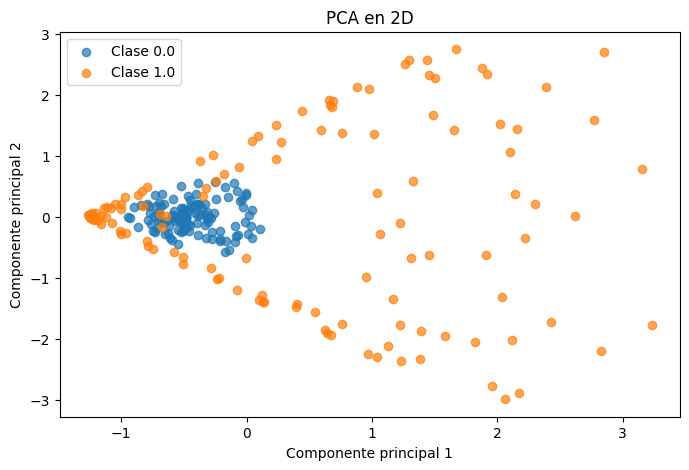

In [17]:
from sklearn.decomposition import PCA

# Escalar todos los datos de X solo para la visualización
X_escalado = StandardScaler().fit_transform(X)

# Reducir X a 2 dimensiones
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_escalado)

# Gráfico PCA
plt.figure(figsize=(8, 5))

for clase in np.unique(y):
    plt.scatter(
        X_pca[y == clase, 0],
        X_pca[y == clase, 1],
        label=f"Clase {clase}",
        alpha=0.7
    )

plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")
plt.title("PCA en 2D")
plt.legend()
plt.show()

In [18]:
# 4. Dividir y escalar
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


# Escalar
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [19]:
# 5. Crear y entrenar el modelo

# class_weight="balanced" ayuda cuando una clase tiene menos datos
modelo = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)
modelo.fit(X_train, y_train)

# modelo = DecisionTreeClassifier(max_depth=3, random_state=42)
# modelo.fit(X_train, y_train)

# modelo = RandomForestClassifier(n_estimators=100, max_depth=3, random_state=42)
# modelo.fit(X_train, y_train)

# modelo = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)
# modelo.fit(X_train, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

Accuracy: 0.74
Precision: 0.875
Recall: 0.56
F1: 0.6829268292682927
AUC: 0.6799999999999999


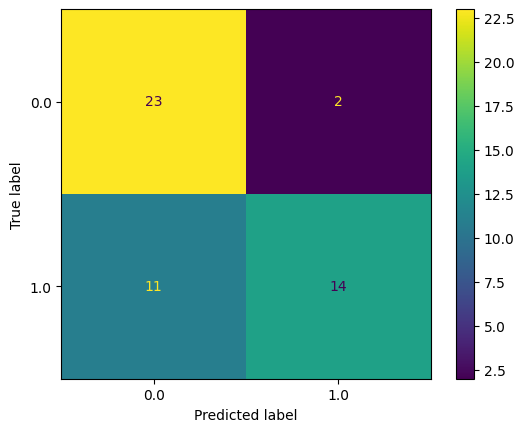

In [20]:
# 6. Evaluar el modelo
y_pred = modelo.predict(X_test)
y_prob = modelo.predict_proba(X_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1:", f1_score(y_test, y_pred, zero_division=0))
print("AUC:", roc_auc_score(y_test, y_prob))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.show()

In [12]:
# 7. Predecir un dato nuevo
# Debe tener la misma cantidad y orden de variables que X
dato_nuevo = np.array([[10, 25, 1, 500]])
dato_nuevo = scaler.transform(dato_nuevo)

prediccion = modelo.predict(dato_nuevo)[0]
probabilidad = modelo.predict_proba(dato_nuevo)[0, 1]

print("Clase predicha:", prediccion)
print("Probabilidad:", probabilidad)

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


ValueError: X has 4 features, but StandardScaler is expecting 2 features as input.

In [ ]:
import joblib

# Guardar el modelo, el escalador y las columnas utilizadas
archivo_final = {
    "modelo": modelo,
    "scaler": scaler,
    "columnas": df.drop(columns=["objetivo"]).columns.tolist()
}

joblib.dump(archivo_final, "nombre_modelo.joblib")

print("Modelo guardado correctamente.")

In [ ]:
# # En otro notebook o aplicación cargar el modelo guardado

# archivo_cargado = joblib.load("nombre_modelo.joblib")

# modelo_cargado = archivo_cargado["modelo"]
# scaler_cargado = archivo_cargado["scaler"]
# columnas = archivo_cargado["columnas"]

# print("Modelo cargado correctamente.")
# print("Columnas esperadas:", columnas)

# dato_nuevo = np.array([[10, 25, 1, 500]])

# dato_nuevo_escalado = scaler_cargado.transform(dato_nuevo)

# prediccion = modelo_cargado.predict(dato_nuevo_escalado)[0]
# probabilidad = modelo_cargado.predict_proba(dato_nuevo_escalado)[0, 1]

# print("Clase predicha:", prediccion)
# print("Probabilidad:", probabilidad)